# Tema : Modelos SARIMA
![](src/img/logo_utb.png){width=40%}
![](src/img/logo_etd.png){width=40%}
- **Profesor:**
- **Fernando Salcedo Mejía, Eco Msc.**
- Programa de Ciencias de Datos | Escuela de transformación digital.
- 2026-1

## Ejemplo 1. Empleo mensual en el sector de ocio y hostelería en EE. UU

Describiremos la modelización ARIMA estacional utilizando datos mensuales de empleo en Estados Unidos para los trabajos de ocio y hospitalidad desde enero de 2001 hasta septiembre de 2019.

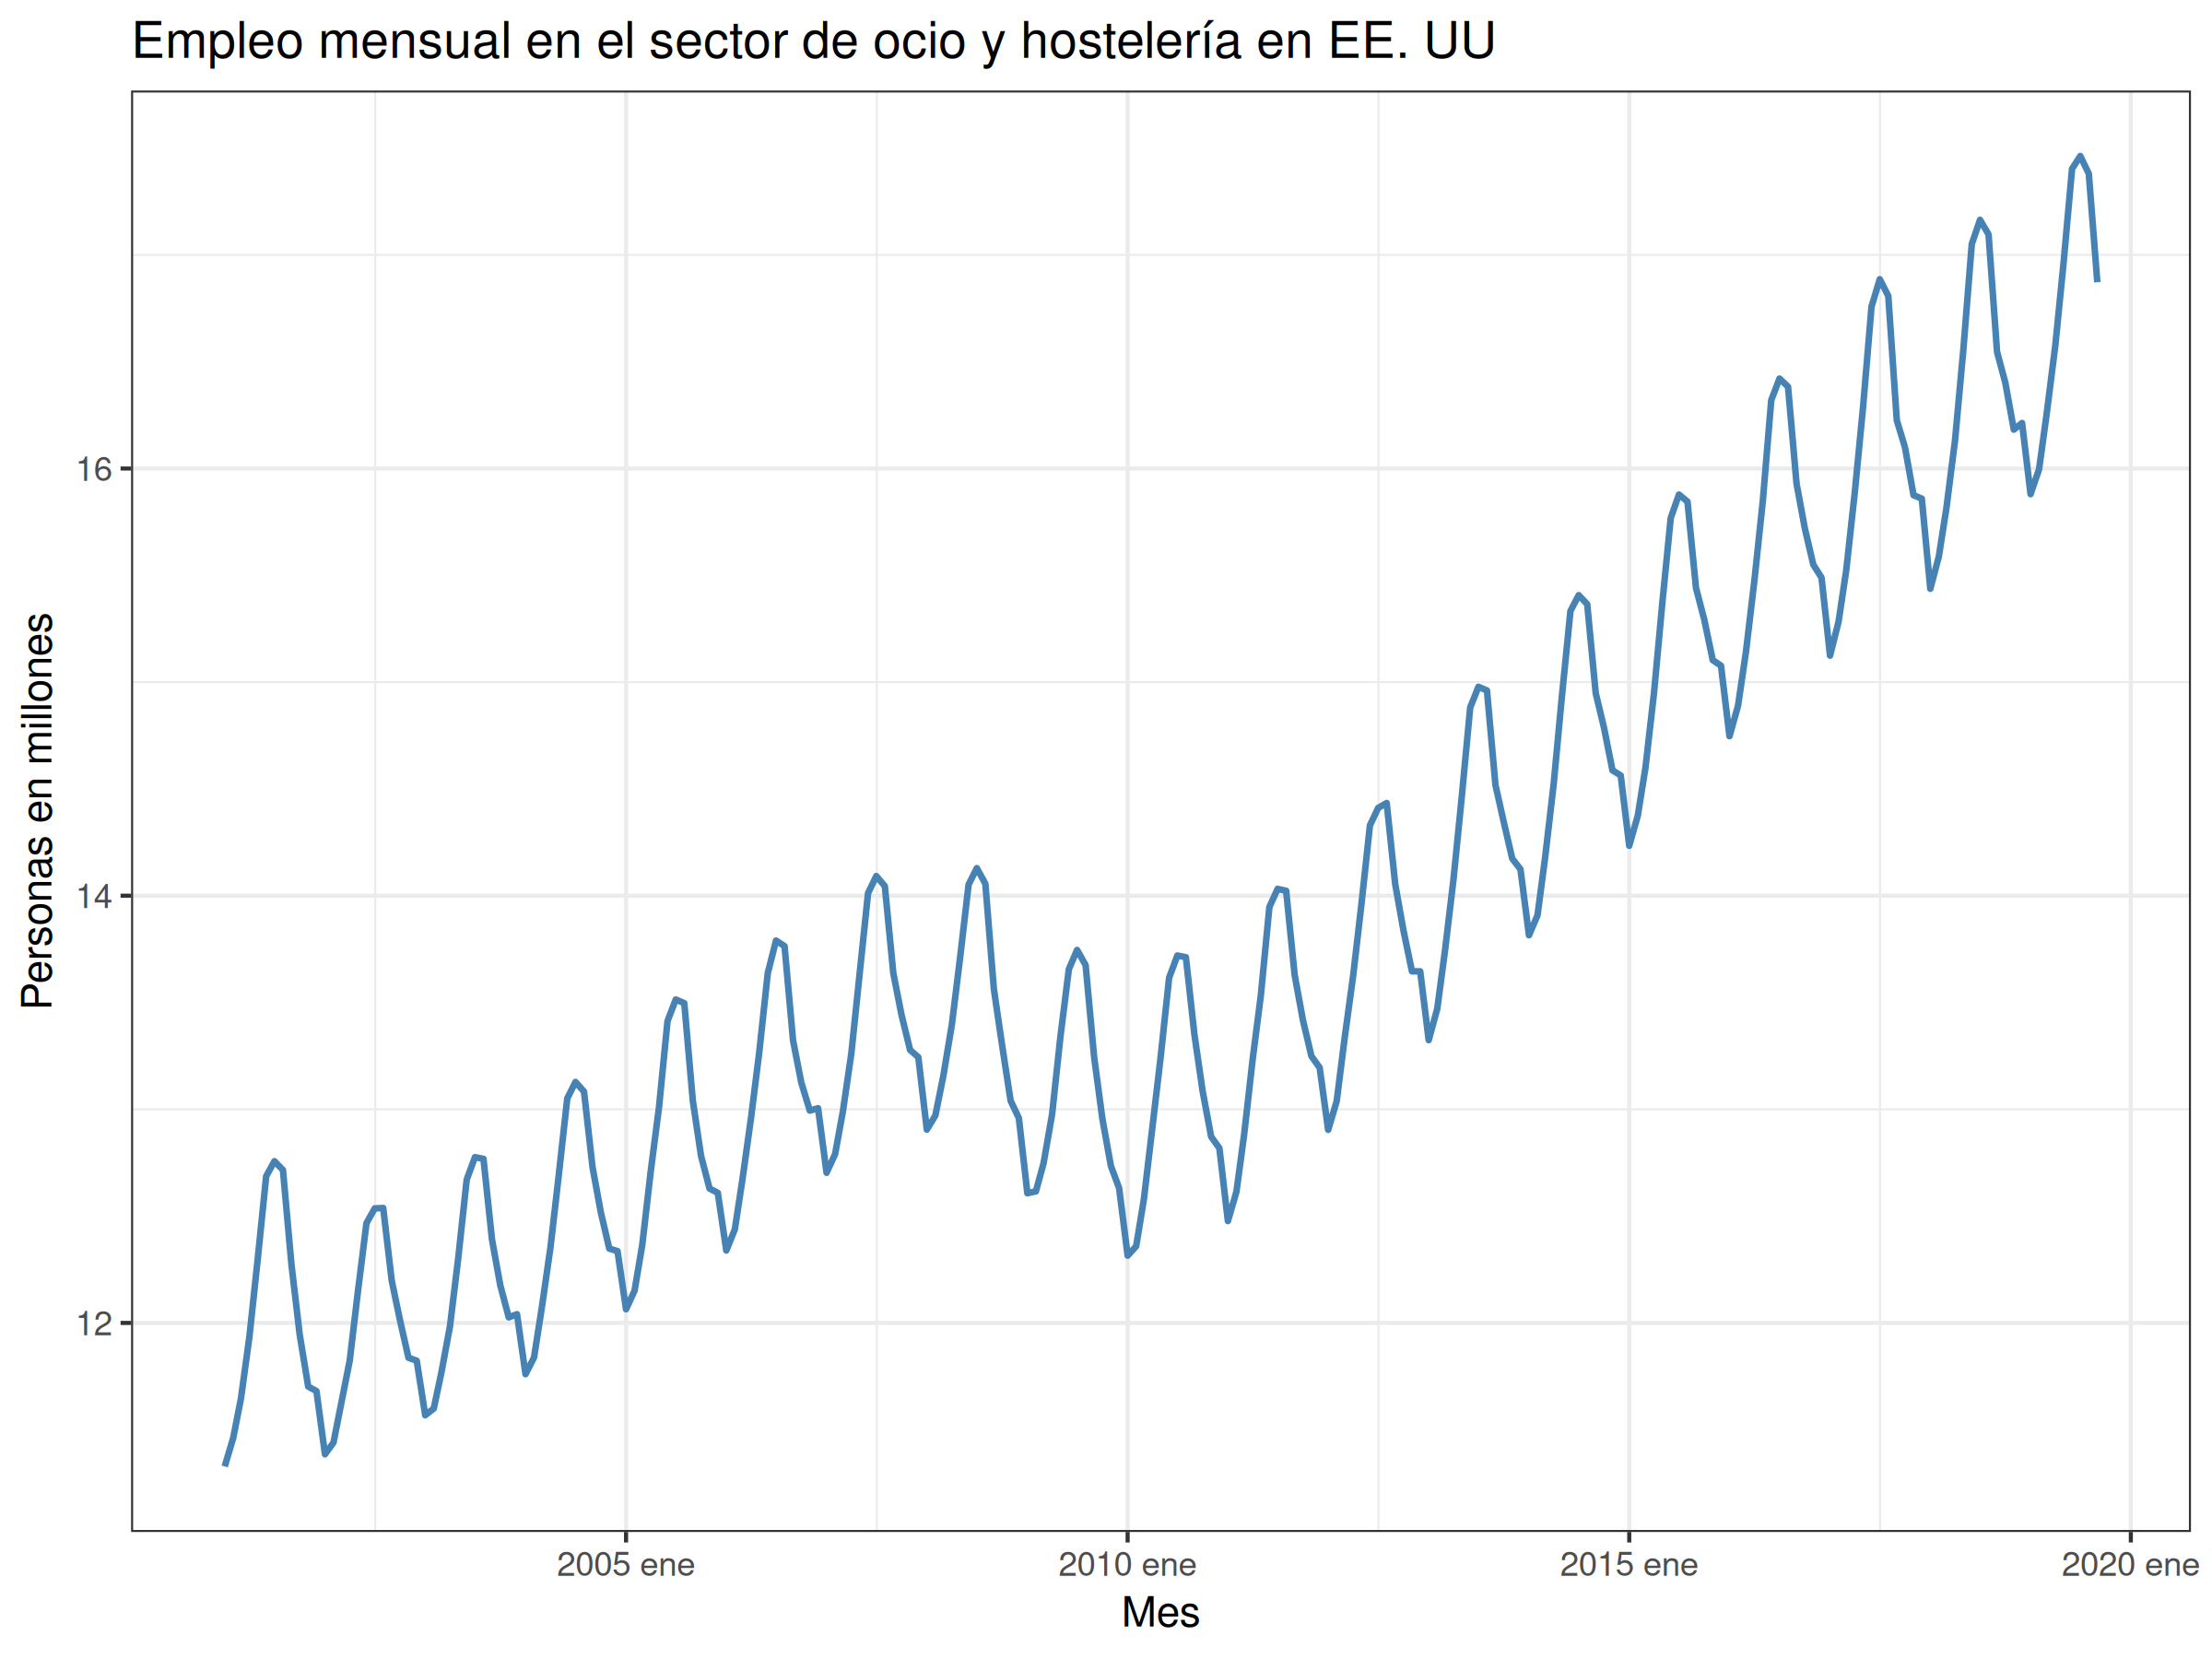

In [1]:
# Instalar todas las librerias necesarias previamente desde r-requirements.txt
suppressPackageStartupMessages({
  library(tidyverse)
  library(fable)       # Modelos ARIMA / SARIMA
  library(feasts)      # ACF, PACF y descomposición
  library(tsibble)     # Estructura de datos para series de tiempo
  library(ggtime)      # Visualización
  library(tseries)     # Pruebas ADF y KPSS
  library(patchwork)   # Combinar gráficos
})

# tamaño de los graficos
options(repr.plot.width = 8,
        repr.plot.height = 6,
        repr.plot.res = 300,
        repr.plot.pointsize = 14)

set_theme(theme_bw())

# leer y ajustar datos
serie_us_employment <- read_csv("../data/us_employment.csv", show_col_types = FALSE) |>
  filter(ds >= as.Date("2001-01-01"), unique_id == "Leisure and Hospitality") |>
  mutate(
    ds = yearmonth(ds),
    y  = y / 1e3
  ) |>
  as_tsibble(index = ds)

# grafico serie
serie_us_employment |>
  autoplot(y, colour = "steelblue", linewidth = 0.8) +
  labs(
    title = "Empleo mensual en el sector de ocio y hostelería en EE. UU",
    x = "Mes", y = "Personas en millones"
  )

Los datos son claramente no estacionarios, con una fuerte estacionalidad y una tendencia no lineal, por lo que primero tomaremos una diferencia estacional. Los datos con diferencia estacional se muestran en la figura siguiente.

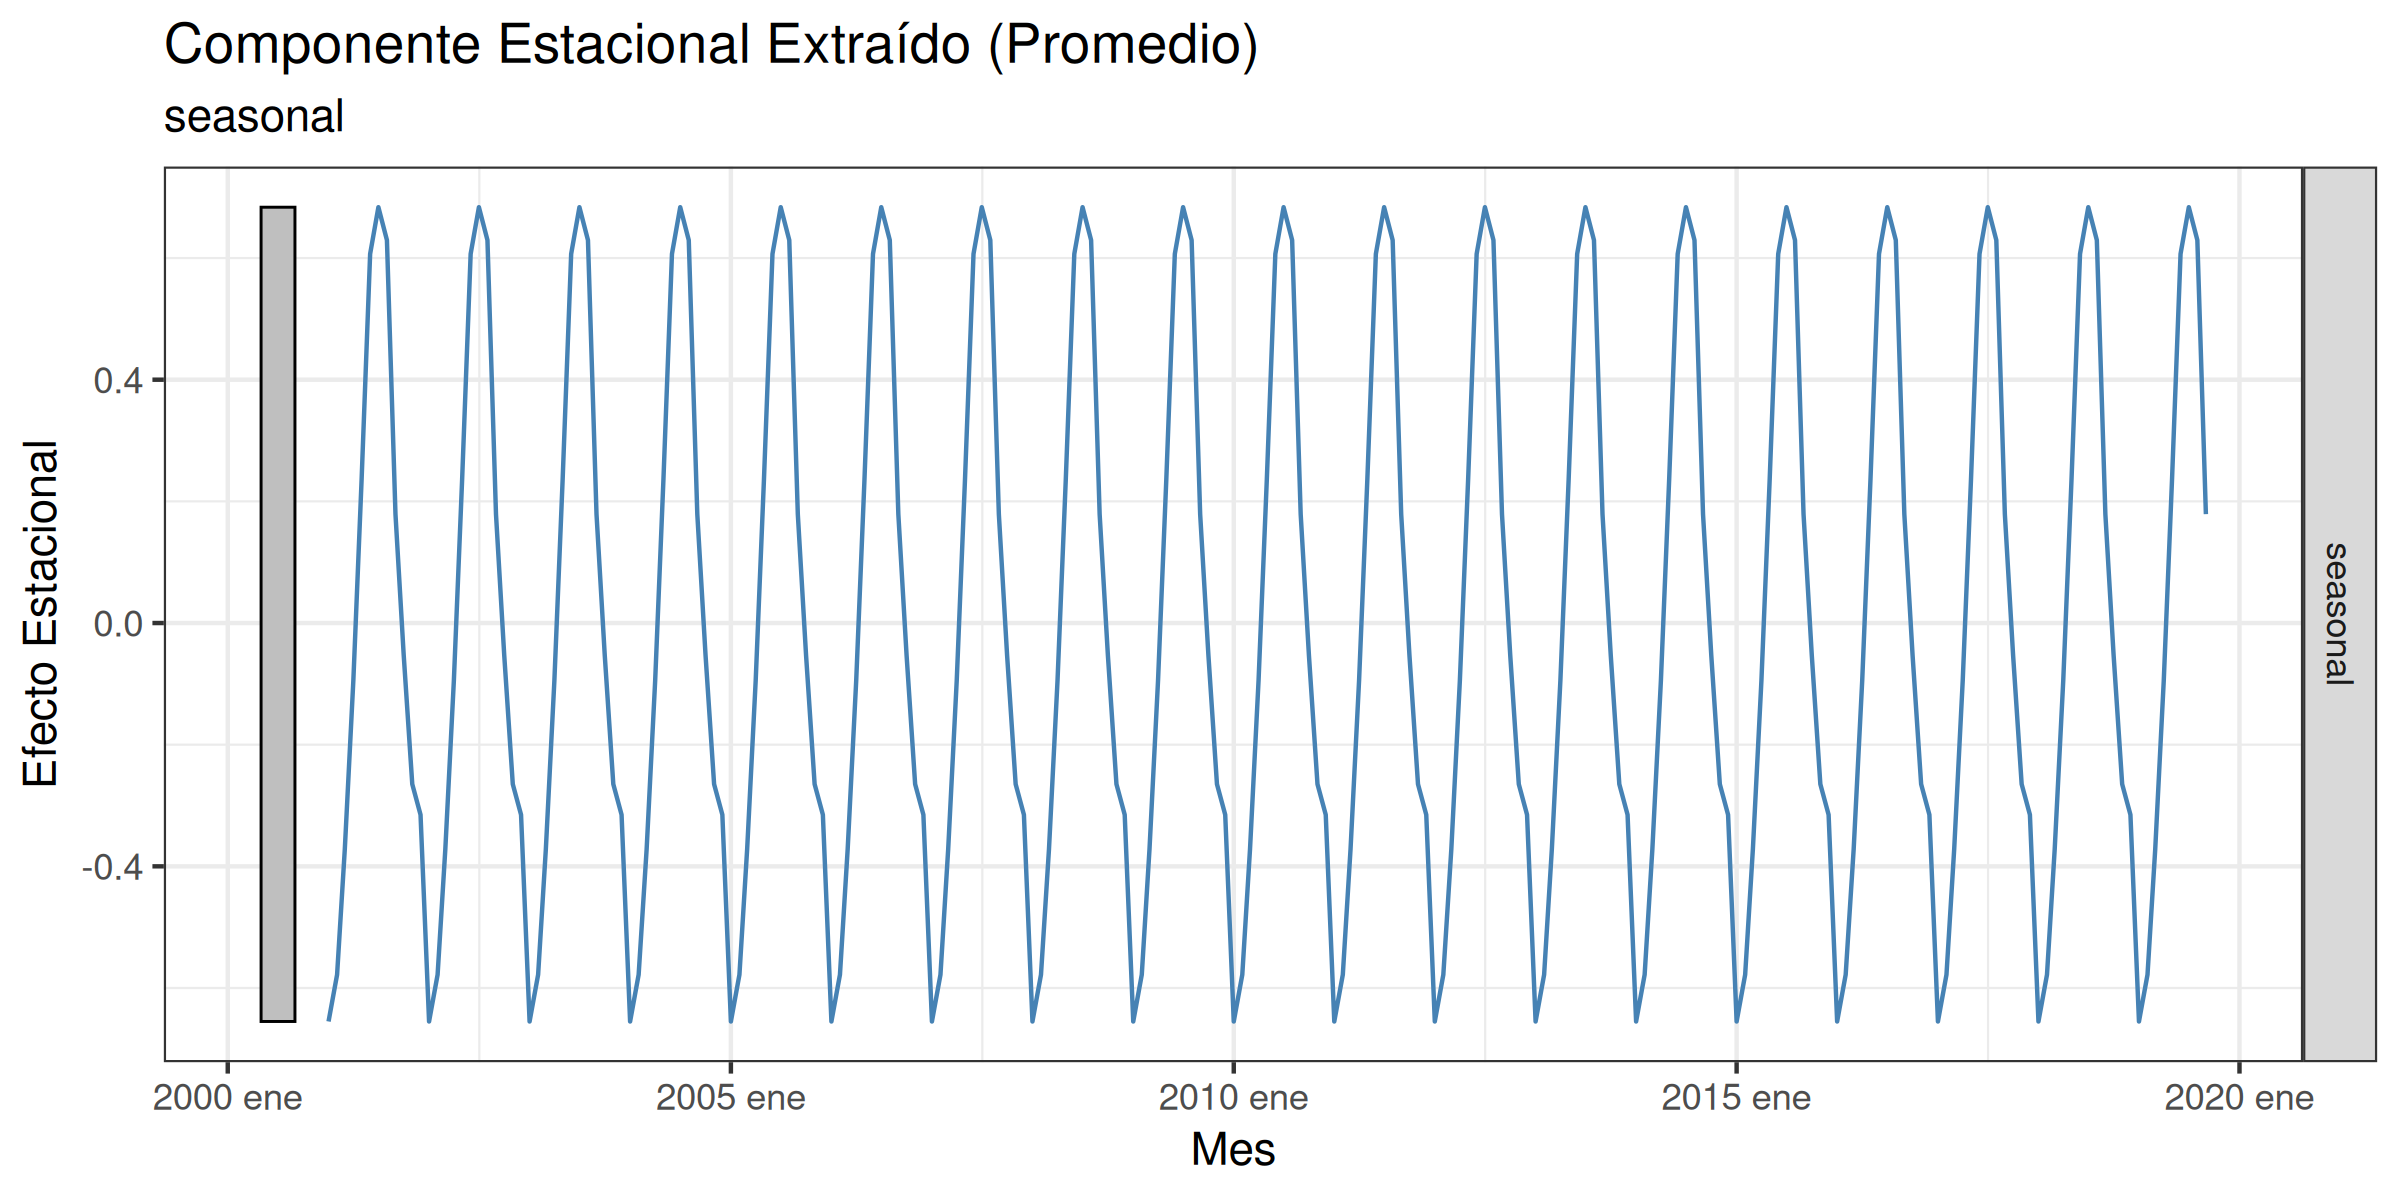

In [2]:
# Descomposición aditiva clásica
descomposicion <- serie_us_employment |>
  model(classical_decomposition(y, type = "additive")) |>
  components()

# Graficar solo el componente estacional
options(repr.plot.height = 4)
descomposicion |>
  autoplot(seasonal, colour = "steelblue") +
  labs(title = "Componente Estacional Extraído (Promedio)", x = "Mes", y = "Efecto Estacional")
options(repr.plot.height = 6)

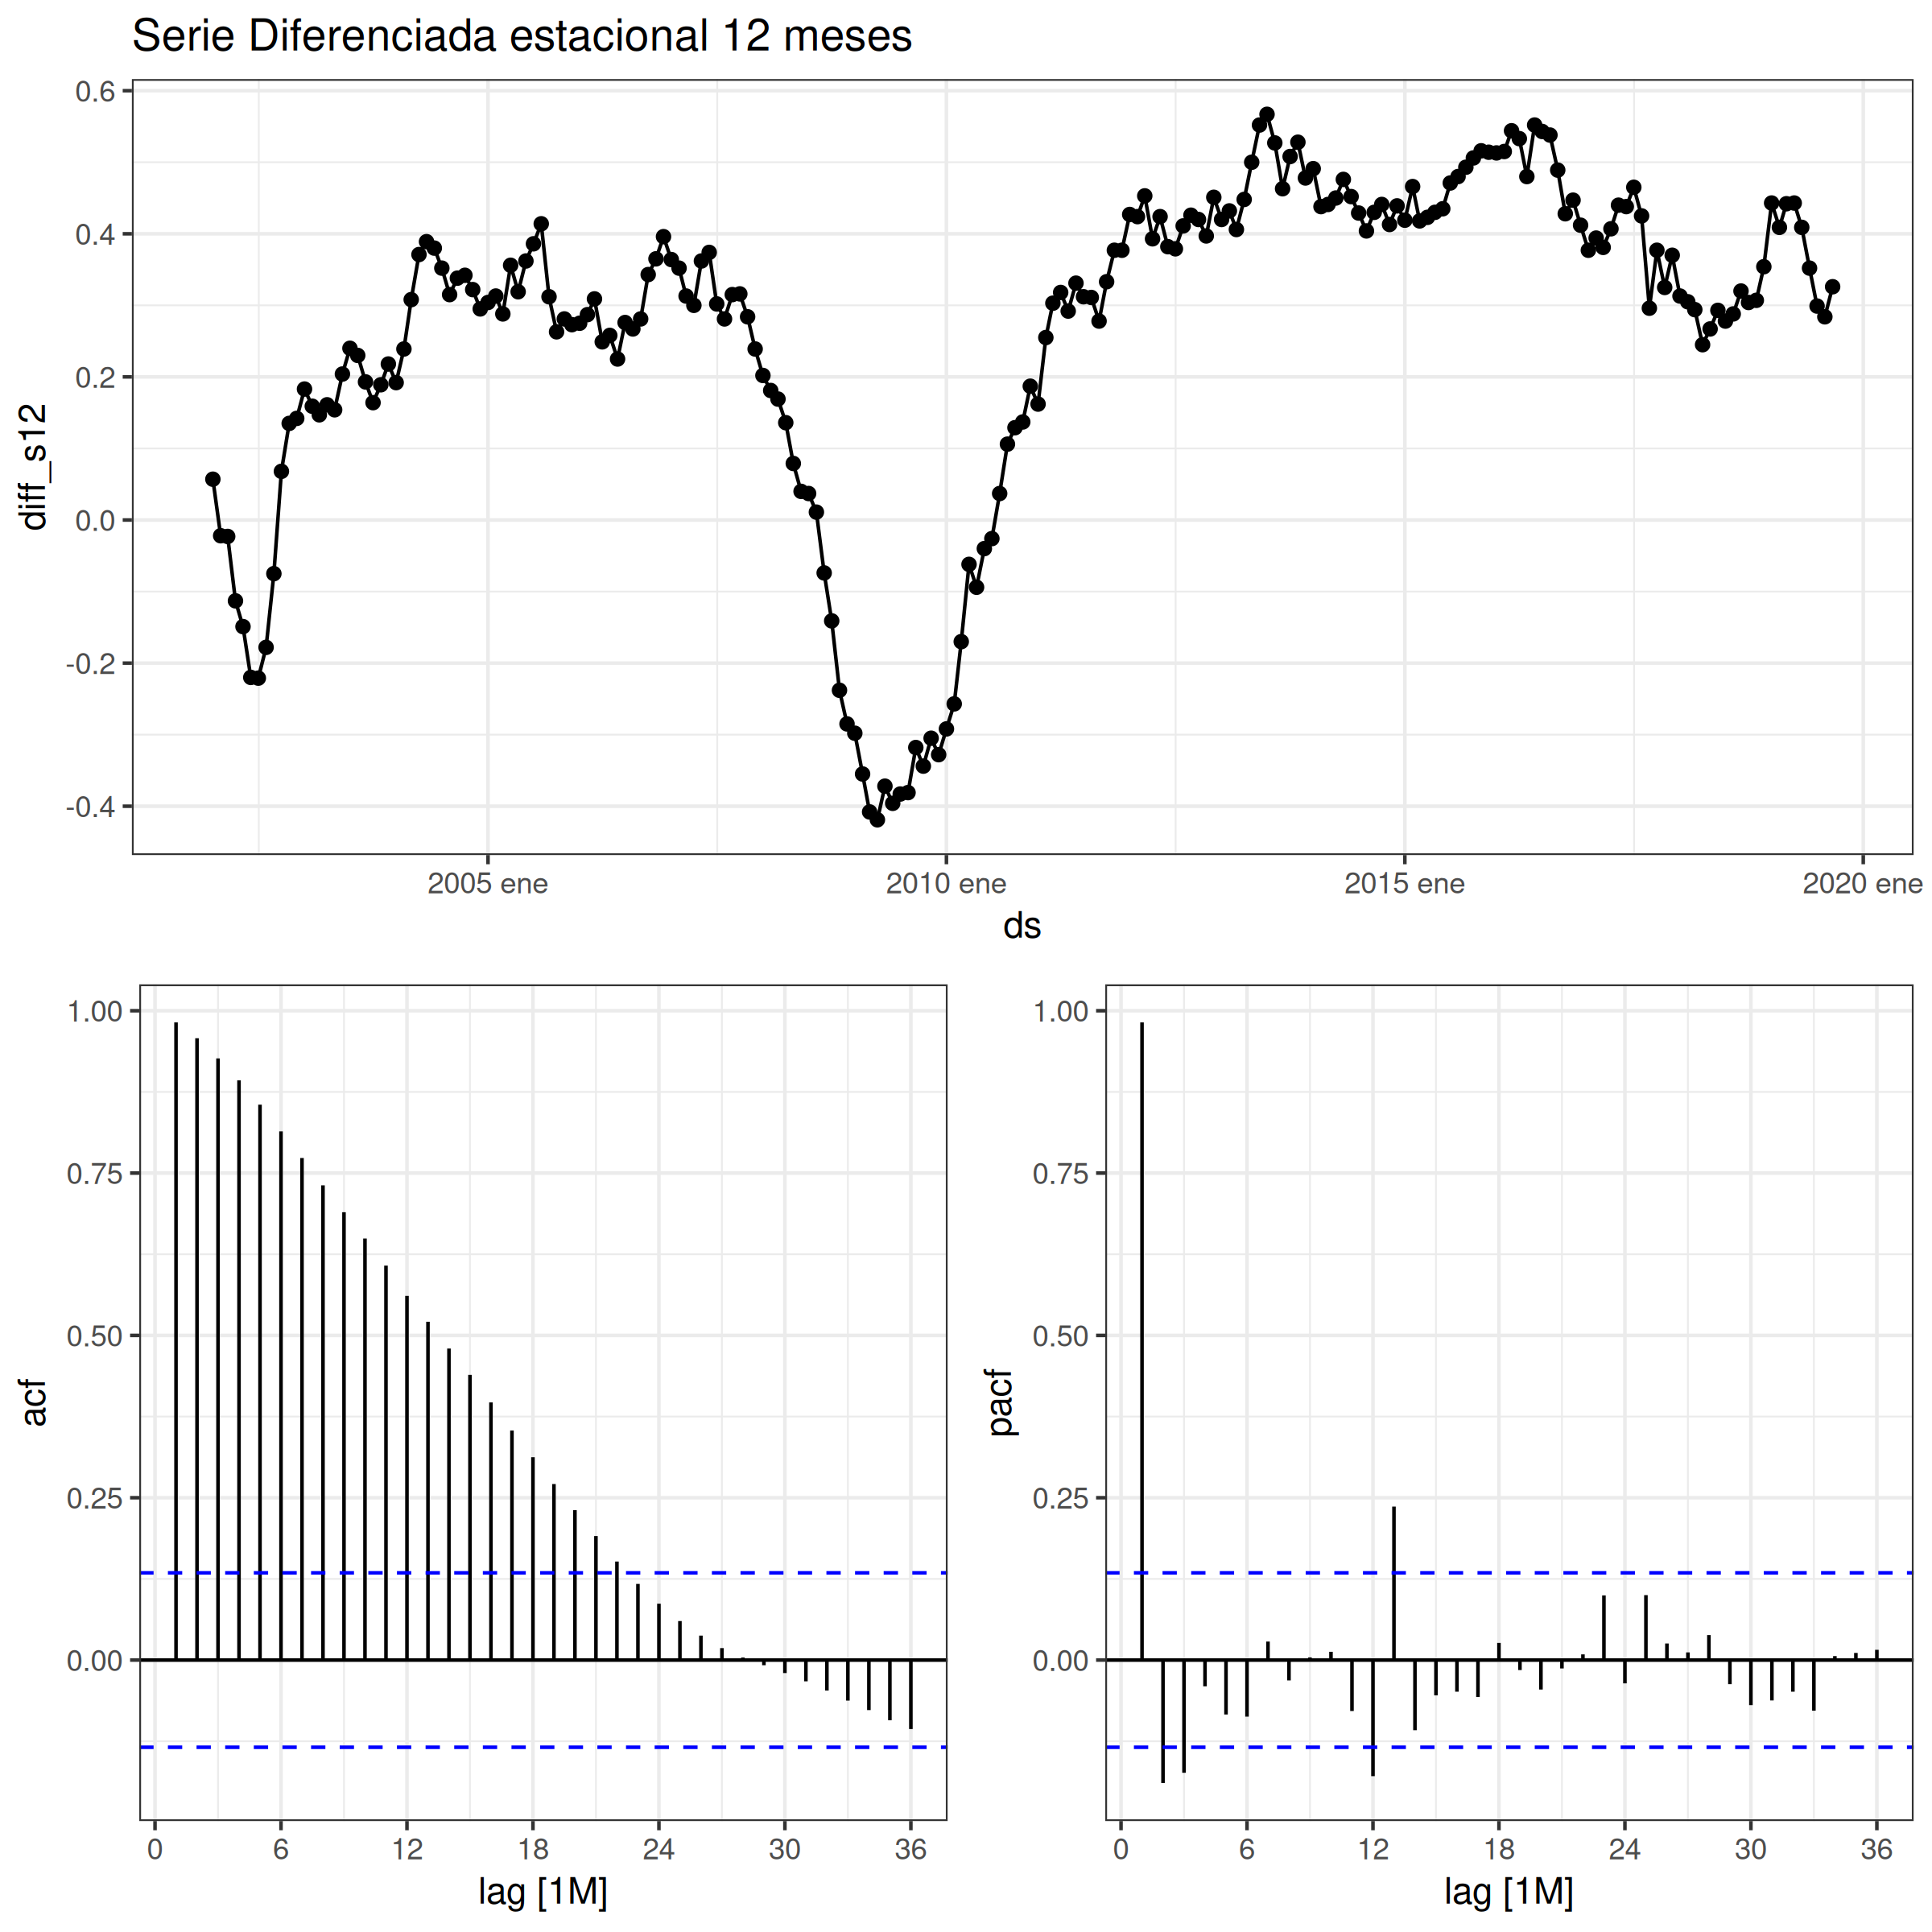

In [3]:
# Diferencia estacional
options(repr.plot.height = 8)
serie_us_employment |>
  mutate(diff_s12 = difference(y, 12)) |>
  filter(!is.na(diff_s12)) |>
  gg_tsdisplay(diff_s12, plot_type = "partial", lag_max = 36) +
  labs(title = "Serie Diferenciada estacional 12 meses")

Estos también son claramente no estacionarios, por lo que tomamos una primera diferencia adicional, ver figura siguiente.

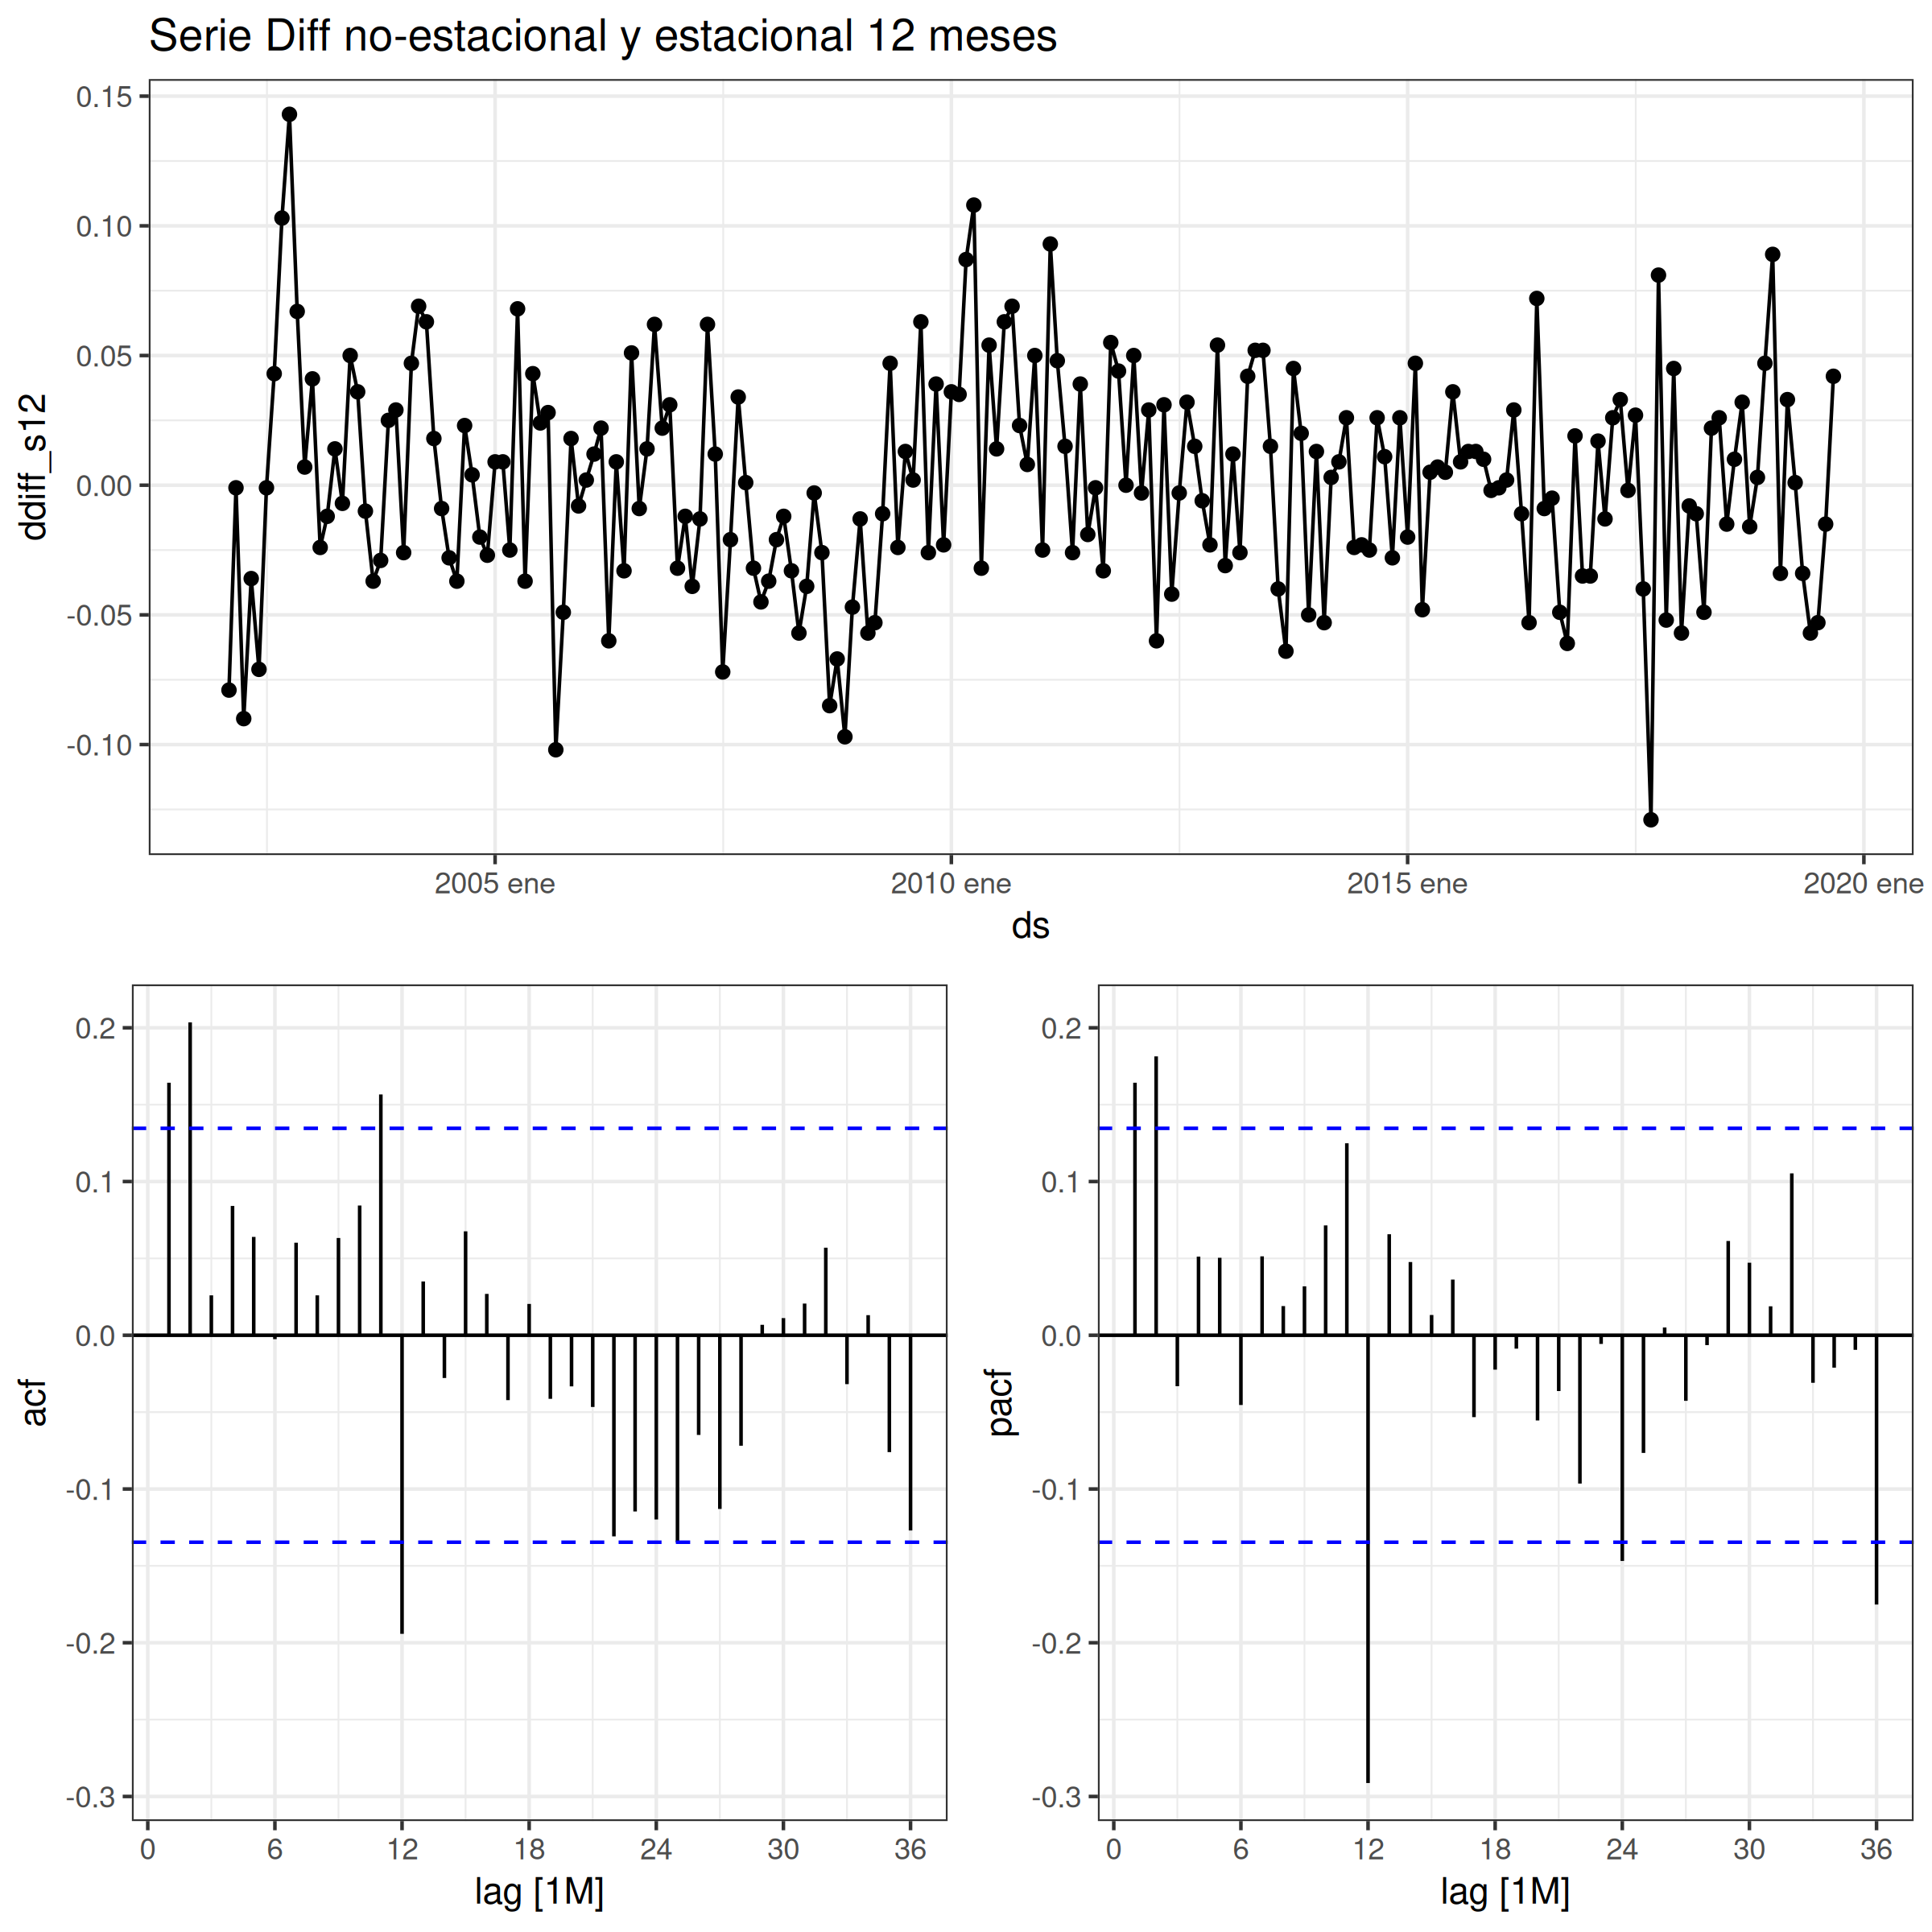

In [4]:
# Diferencia no estacional sobre la serie con diferencia estacional
serie_us_employment |>
  mutate(ddiff_s12 = difference(difference(y, 12))) |>
  filter(!is.na(ddiff_s12)) |>
  gg_tsdisplay(ddiff_s12, plot_type = "partial", lag_max = 36) +
  labs(title = "Serie Diff no-estacional y estacional 12 meses")
options(repr.plot.height = 6)

In [5]:
test_estacionariedad <- function(datos) {
  datos <- as.numeric(na.omit(datos))
  # Augmented Dickey-Fuller (H0: la serie tiene raíz unitaria)
  adf_result  <- suppressWarnings(adf.test(datos))
  # KPSS (H0: la serie es estacionaria en nivel)
  kpss_result <- suppressWarnings(kpss.test(datos, null = "Level"))

  # Tabla de resultados
  tibble(
    Test         = c("Prueba Augmented Dickey-Fuller (ADF)", "Prueba KPSS"),
    Estadistico  = round(c(adf_result$statistic, kpss_result$statistic), 4),
    `P-valor`    = round(c(adf_result$p.value, kpss_result$p.value), 4),
    Estacionario = c(if_else(adf_result$p.value < 0.05, "Sí", "No"),
                     if_else(kpss_result$p.value < 0.05, "No", "Sí"))
  )
}

ddiff_s12 <- serie_us_employment |>
  mutate(ddiff = difference(difference(y, 12)))

test_estacionariedad(ddiff_s12$ddiff)

# fable también sugiere el número de diferencias necesarias
serie_us_employment |>
  features(y, list(unitroot_nsdiffs, \(x) unitroot_ndiffs(difference(x, 12))))

Test,Estadistico,P-valor,Estacionario
<chr>,<dbl>,<dbl>,<chr>
Prueba Augmented Dickey-Fuller (ADF),-5.3409,0.01,Sí
Prueba KPSS,0.0849,0.10,Sí


nsdiffs,ndiffs
<int>,<int>
1,1


## Definición del modelo
- Nuestro objetivo ahora es encontrar un modelo ARIMA apropiado basándonos en la ACF y la PACF mostradas en la figura anterior.
- El pico significativo en el rezago 2 de la ACF sugiere un componente MA(2) no estacional.
- El pico significativo en el rezago 12 de la ACF sugiere un componente MA(1) estacional.
- En consecuencia, comenzamos con un modelo $ARIMA(0,1,2)(0,1,1)_{12}$, que indica una primera diferencia, una diferencia estacional y componentes MA(2) no estacional y MA(1) estacional.
- Si hubiéramos partido de la PACF, podríamos haber seleccionado un modelo $ARIMA(2,1,0)(0,1,1)_{12}$
- Usando la PACF para seleccionar la parte no estacional del modelo y la ACF para seleccionar la parte estacional. También incluiremos un modelo seleccionado automáticamente.

## Construcción del modelo $SARIMA (0,1,2)(0,1,1)_{12}$
- Parte Regular (0,1,2):
    - p = 0 : No componente autoregresivo
    - d = 1: Estás tomando una diferencia para eliminar la tendencia
    - q = 2: El valor de hoy depende de los errores de los dos meses anteriores
- Parte Estacional (0,1,1,12):
    - P = 0 : No componente autoregresivo
    - D = 1 : Estás restando el valor del mismo mes del año anterior ($Y_t - Y_{t-12}$) para eliminar el patrón anual.
    - Q = 1 : El error de este mes está correlacionado con el error del mismo mes del año pasado.
    - s = 12 : Define el ciclo estacional ocurre cada 12 observaciones.

En `fable` la parte regular se define con `pdq(p, d, q)` y la estacional con `PDQ(P, D, Q)`; el período `s = 12` se toma de la frecuencia mensual de la serie.

In [6]:
# Estimar modelos SARIMA
list_modelos <- serie_us_employment |>
  model(
    `ARIMA(0,1,2)(0,1,1)12` = ARIMA(y ~ pdq(0, 1, 2) + PDQ(0, 1, 1)),
    `ARIMA(2,1,0)(0,1,1)12` = ARIMA(y ~ pdq(2, 1, 0) + PDQ(0, 1, 1)),
    # Búsqueda exhaustiva (revisa todas las combinaciones)
    AutoSARIMA              = ARIMA(y, stepwise = FALSE, approximation = FALSE)
  )

list_modelos

"ARIMA(0,1,2)(0,1,1)12","ARIMA(2,1,0)(0,1,1)12",AutoSARIMA
<model>,<model>,<model>
"<ARIMA(0,1,2)(0,1,1)[12]>","<ARIMA(2,1,0)(0,1,1)[12]>","<ARIMA(2,1,0)(1,1,1)[12]>"


In [7]:
comparar_modelos_arima <- function(modelos) {
  glance(modelos) |>
    select(Modelo = .model, AIC, AICc, BIC, `Log-Lik` = log_lik, sigma2) |>
    left_join(
      accuracy(modelos) |> select(Modelo = .model, RMSE, MAE),
      by = "Modelo"
    ) |>
    arrange(AICc) |>
    mutate(Ranking = row_number(), .before = 1)
}

tabla_modelos <- comparar_modelos_arima(list_modelos)
tabla_modelos

cat("Mejor modelo (menor AICc):", tabla_modelos$Modelo[1], " →  AICc:", tabla_modelos$AICc[1], "\n")

Ranking,Modelo,AIC,AICc,BIC,Log-Lik,sigma2,RMSE,MAE
<int>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,AutoSARIMA,-779.9239,-779.6327,-763.1410,394.9620,0.001415339,0.03617185,0.02831822
2,"ARIMA(2,1,0)(0,1,1)12",-776.1890,-775.9958,-762.7627,392.0945,0.001454293,0.03675428,0.02862004
3,"ARIMA(0,1,2)(0,1,1)12",-774.8994,-774.7062,-761.4731,391.4497,0.001462792,0.03686151,0.02884052


Mejor modelo (menor AICc): AutoSARIMA  →  AICc: -779.6327 


In [8]:
# Reporte modelo
mejor_modelo <- list_modelos |> select(AutoSARIMA)
report(mejor_modelo)

Series: y 
Model: ARIMA(2,1,0)(1,1,1)[12] 

Coefficients:
         ar1     ar2    sar1     sma1
      0.1786  0.1855  0.3295  -0.7507
s.e.  0.0695  0.0679  0.1273   0.0936

sigma^2 estimated as 0.001415:  log likelihood=394.96
AIC=-779.92   AICc=-779.63   BIC=-763.14


**Interpretación**

- La búsqueda automática selecciona un $ARIMA(2,1,0)(1,1,1)_{12}$, que tiene el menor AICc de los tres modelos.
- Parte regular: AR(2) con $\phi_1 = 0.18$ y $\phi_2 = 0.19$ sobre la serie diferenciada.
- Parte estacional: $\Phi_1 = 0.33$ (AR estacional) y $\Theta_1 = -0.75$ (MA estacional). El MA estacional negativo y grande es típico de series con una diferencia estacional.

.model,lb_stat,lb_pvalue
<chr>,<dbl>,<dbl>
AutoSARIMA,16.57691,0.6802512


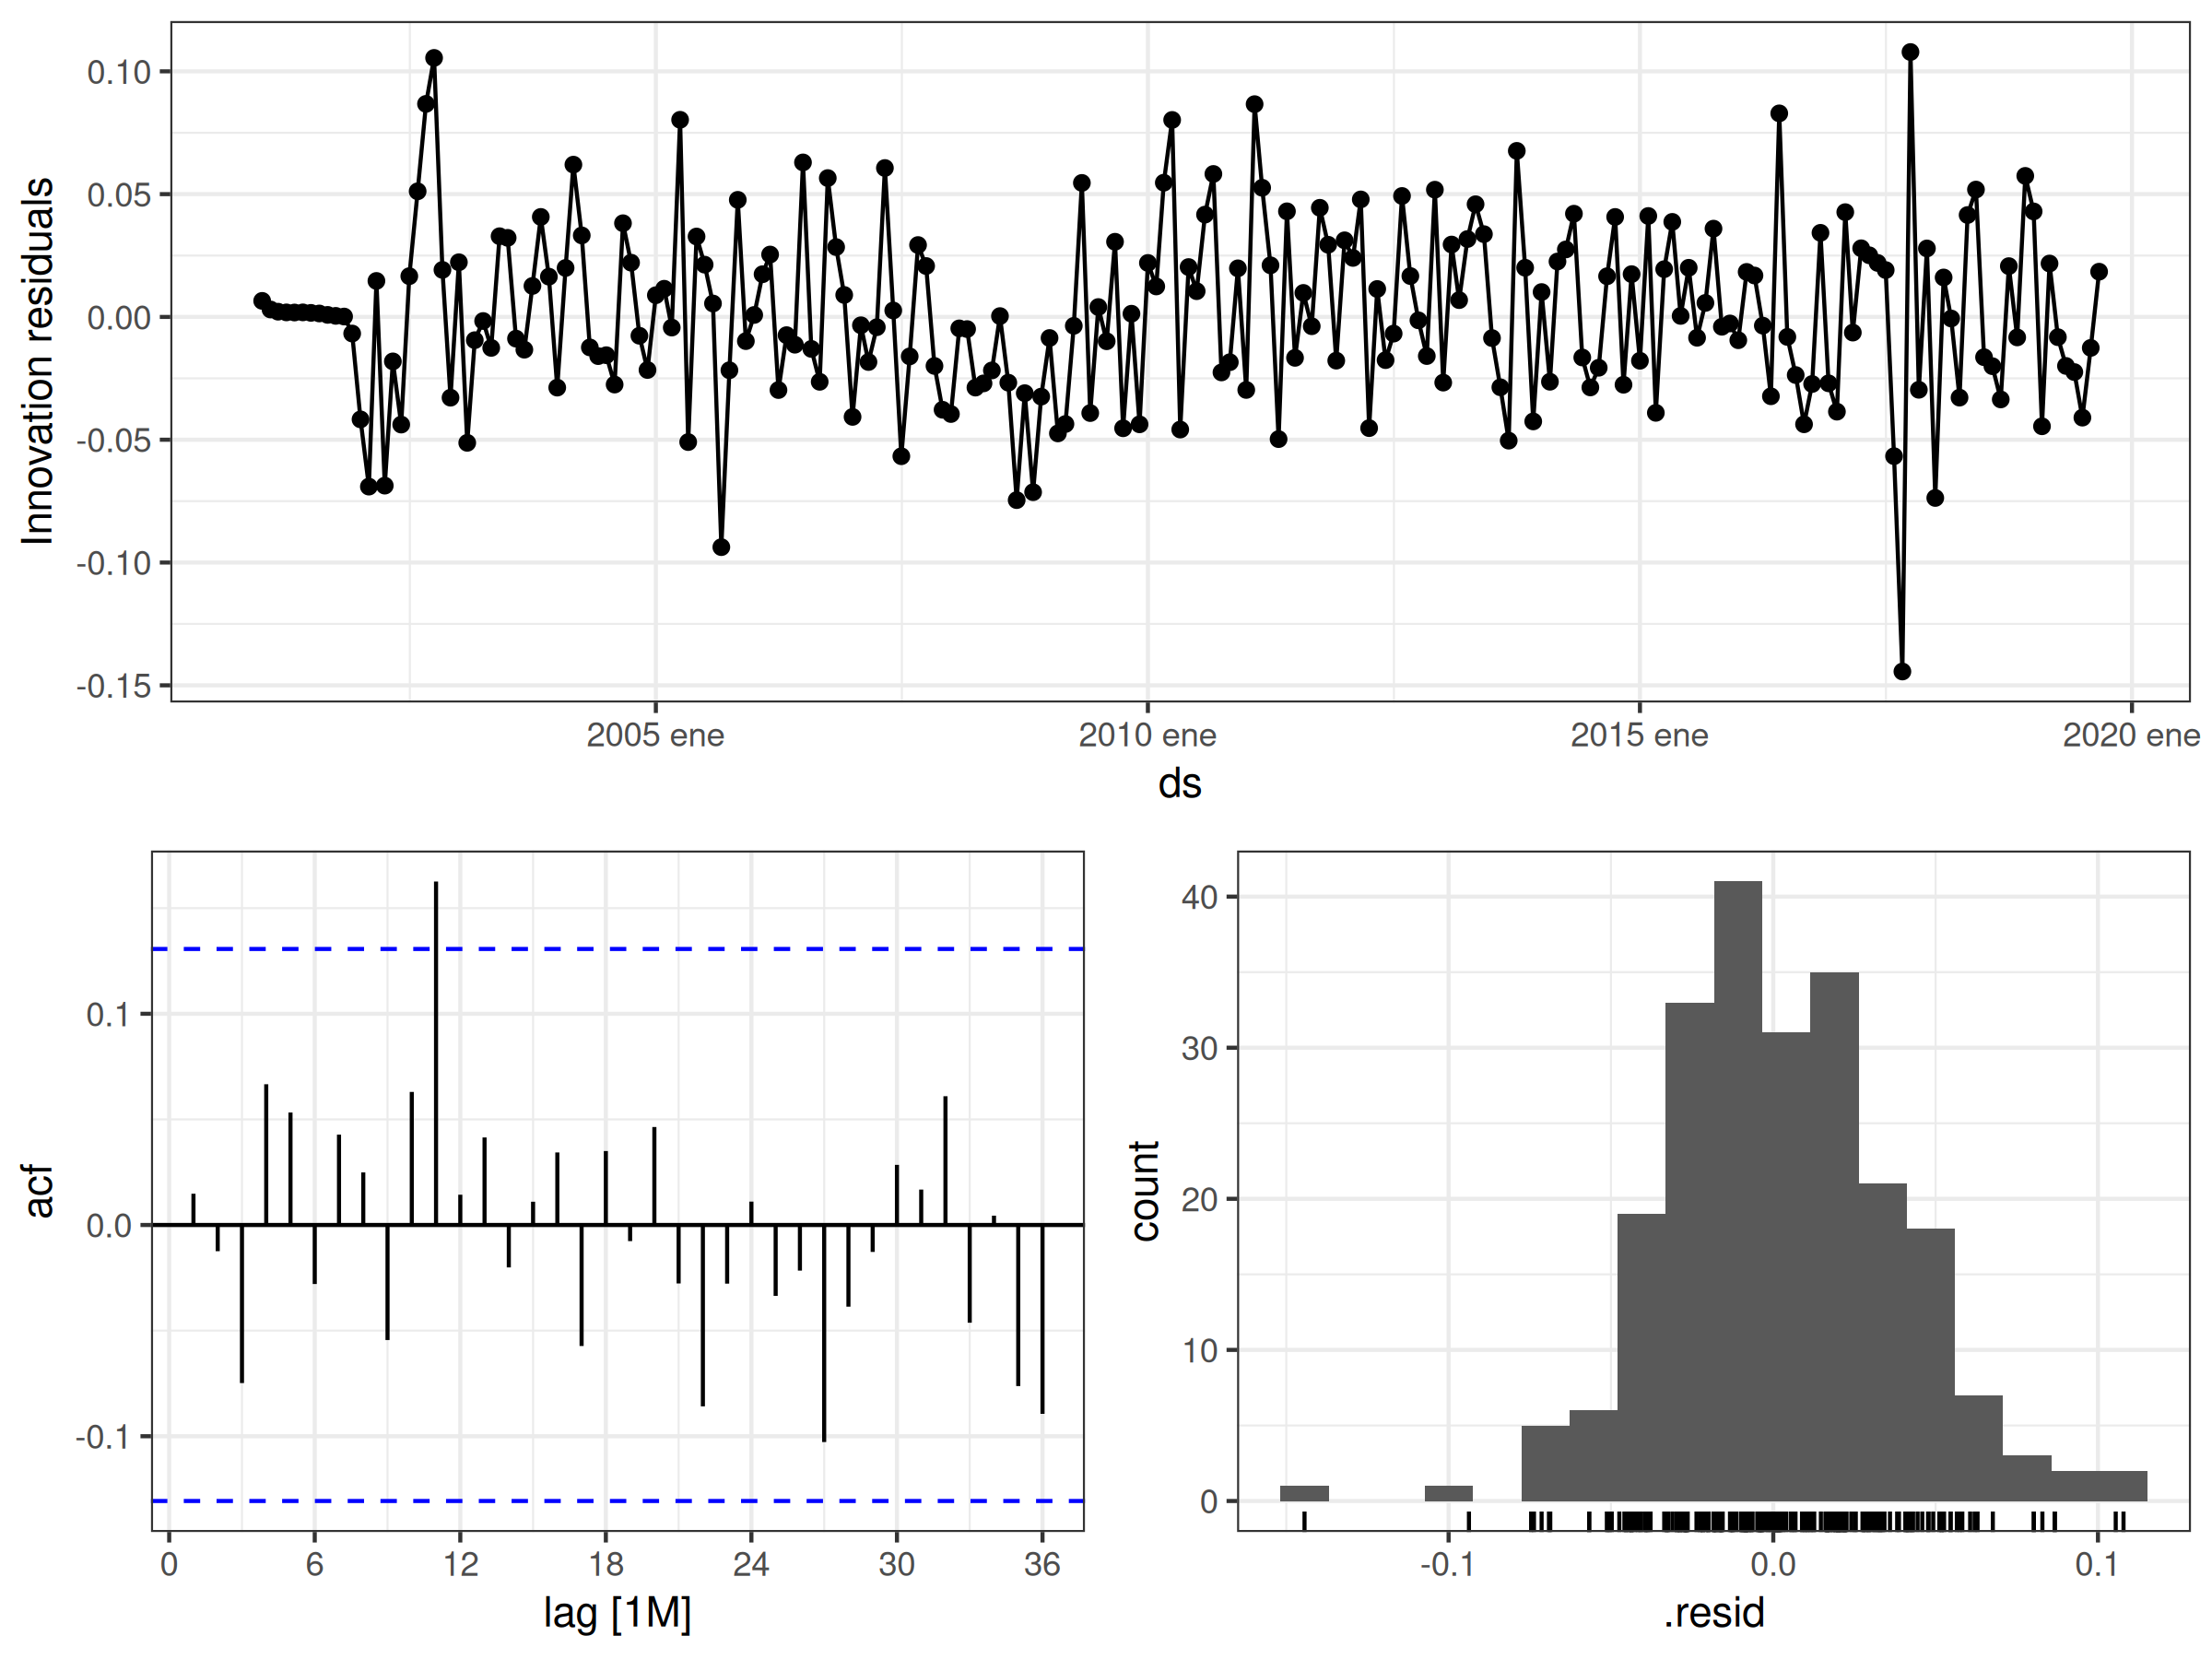

In [9]:
# Verificar ruido blanco
# Diagnostico del modelo
mejor_modelo |> gg_tsresiduals(lag_max = 36)

# Prueba de Ljung-Box: H0 los residuos son ruido blanco
# dof = número de parámetros ARMA estimados
n_parametros <- nrow(tidy(mejor_modelo))
augment(mejor_modelo) |>
  features(.innov, ljung_box, lag = 24, dof = n_parametros)

**Interpretación**

- Los residuos fluctúan alrededor de cero, casi todas las barras del ACF están dentro de las bandas de confianza y el histograma es aproximadamente simétrico.
- La prueba de Ljung-Box (p-valor > 0.05) no rechaza que los residuos sean ruido blanco.

## Pronóstico mejor modelo
Así, ahora contamos con un modelo ARIMA estacional que supera las verificaciones requeridas y está listo para realizar pronósticos.
- Los pronósticos del modelo para los próximos tres años se muestran en la figura siguiente.
- Los pronósticos han captado muy bien el patrón estacional, y la tendencia creciente extiende el patrón reciente. La tendencia en los pronósticos está inducida por la doble diferenciación.

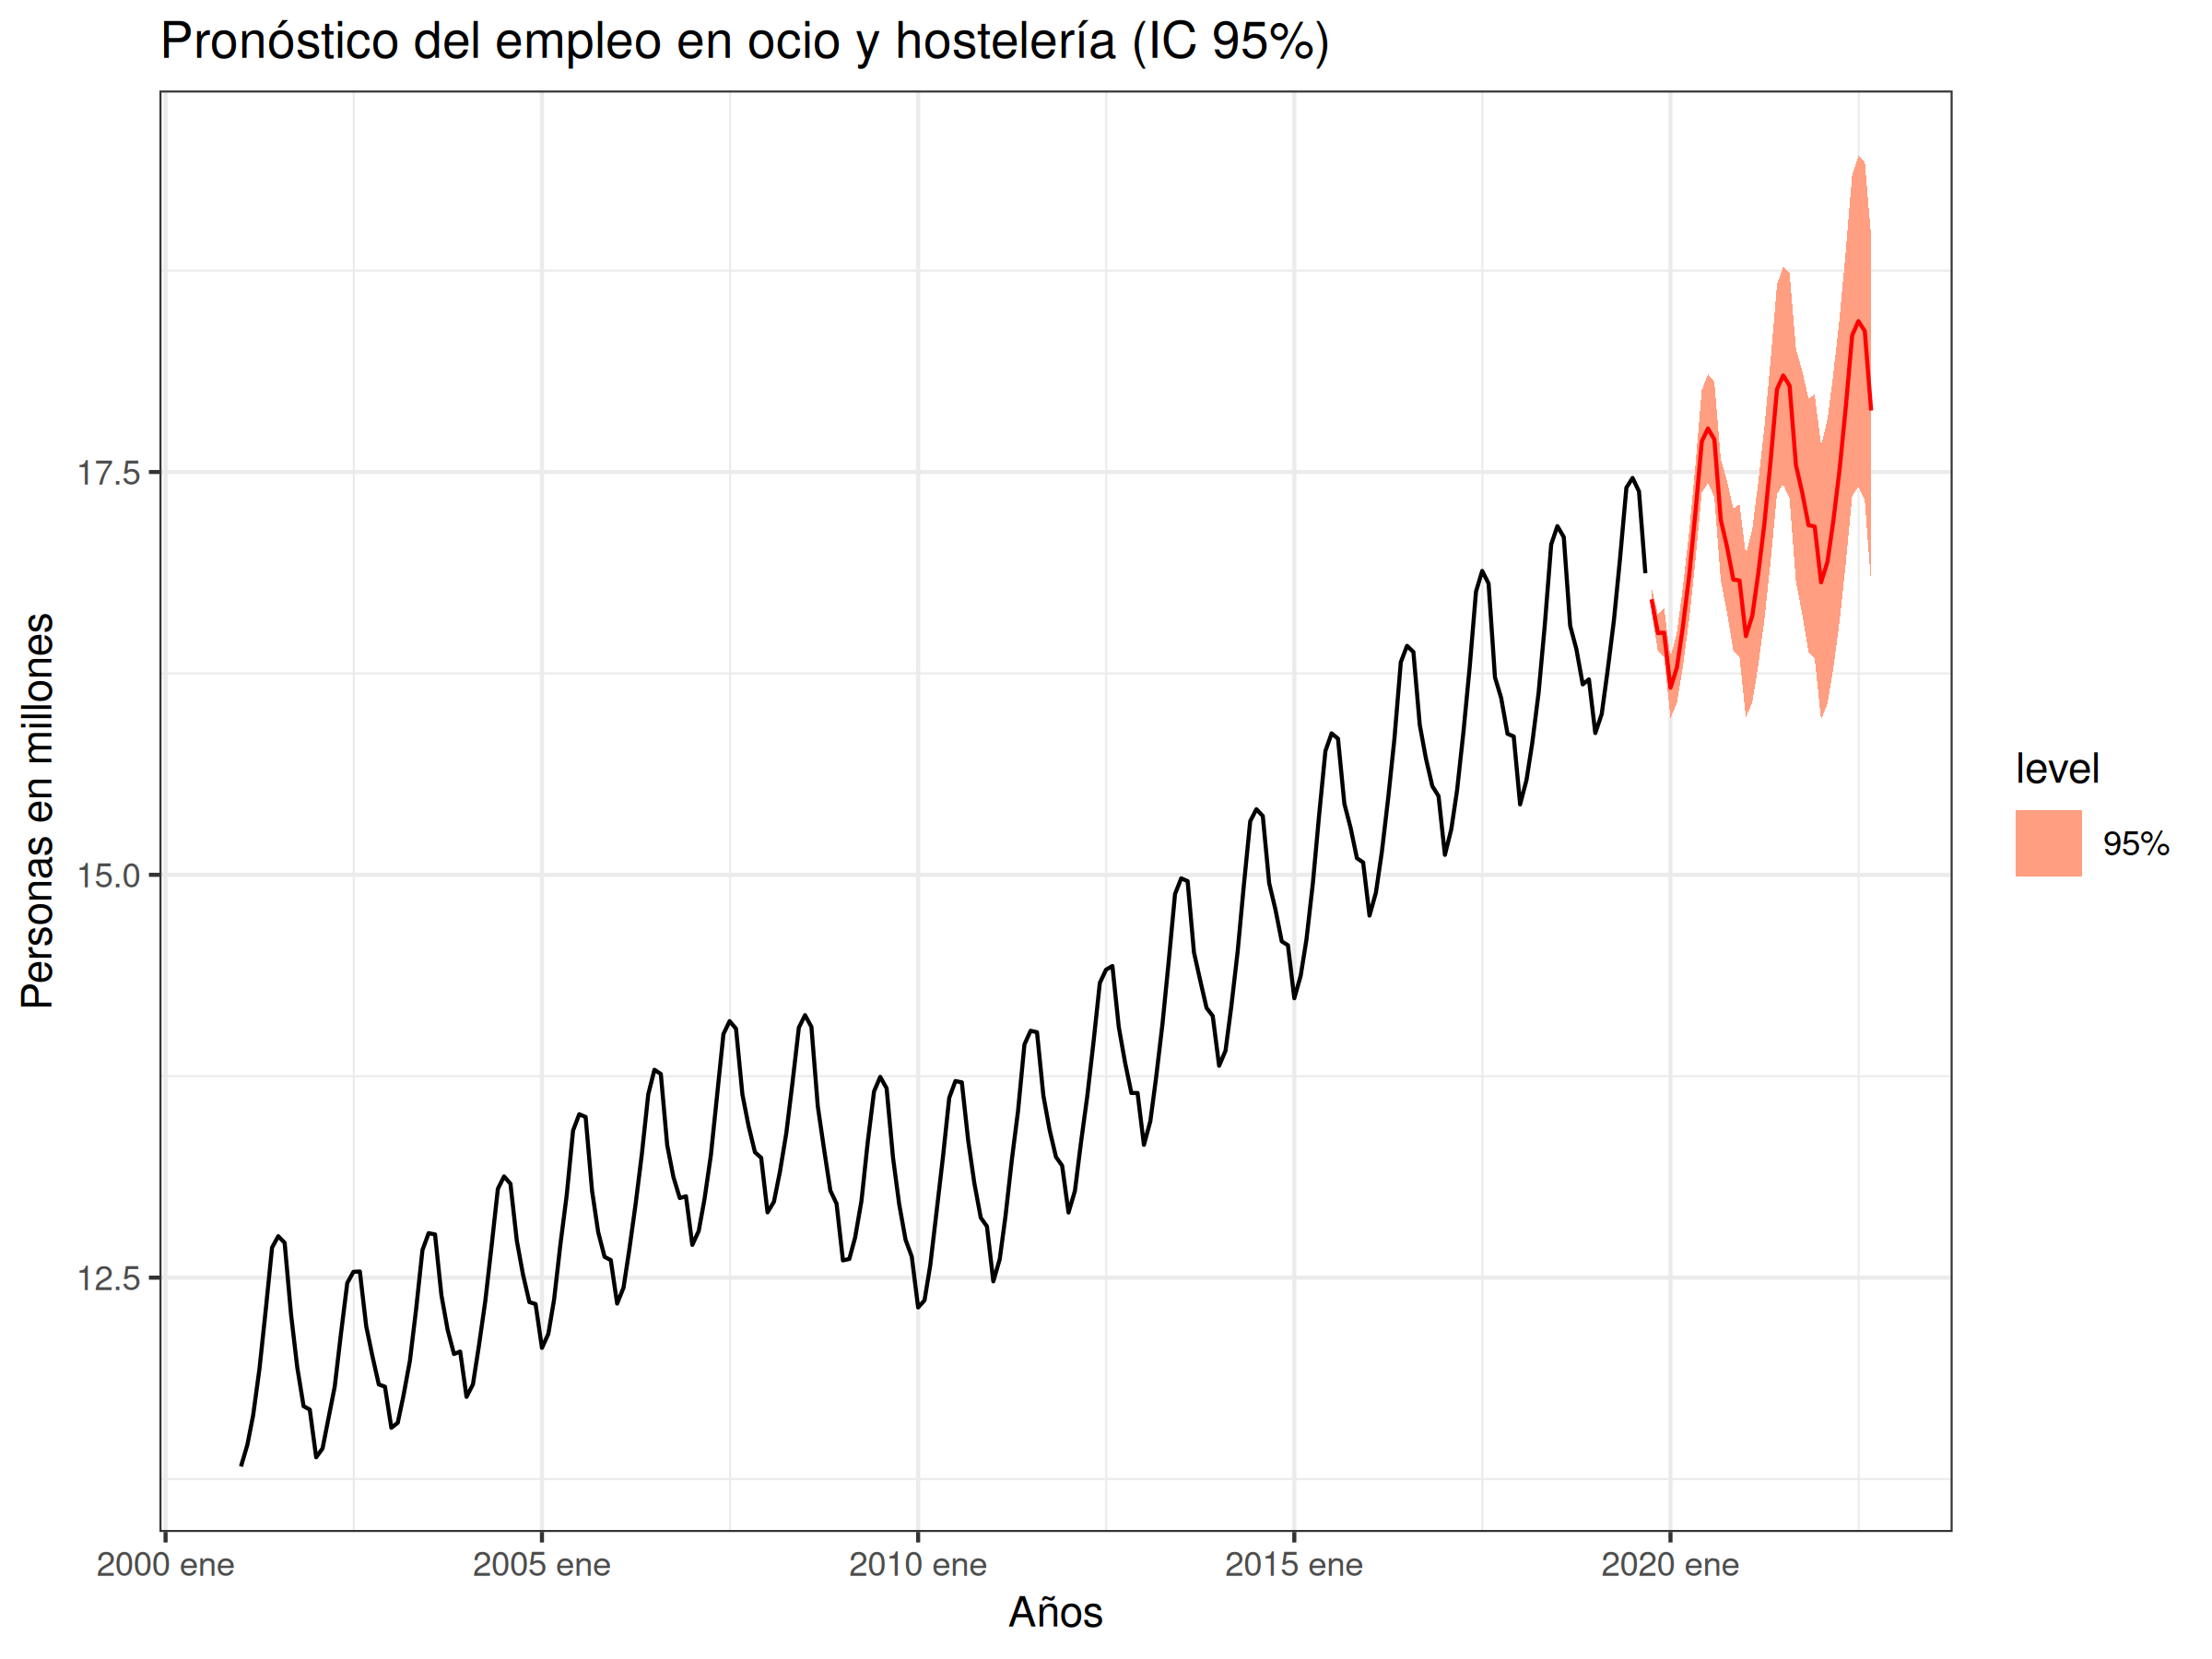

In [10]:
# Pronostico de los proximos 3 años = 12 meses * 3 años  = 36
t_pronostico <- 36

pronostico <- mejor_modelo |>
  forecast(h = t_pronostico)

# Graficar resultados pronostico
pronostico |>
  autoplot(serie_us_employment, level = 95, colour = "red", linetype = "dashed") +
  labs(x = "Años", y = "Personas en millones",
       title = "Pronóstico del empleo en ocio y hostelería (IC 95%)")